# Efficient Vision-Language Adaptation for Remote Sensing
### CLIP + LLM-Generated Prompts + LoRA Few-Shot Adaptation on EuroSAT, with Cross-Domain Generalization Test

**Goal:** Show that (1) LLM-generated descriptive prompts improve zero-shot CLIP on satellite imagery, and
(2) lightweight LoRA adaptation with very few labeled examples closes the gap further — then test whether
the adapted model generalizes to a *different* remote-sensing dataset without retraining.

Runs on a free Google Colab T4 (16GB VRAM). Runtime: GPU (Runtime > Change runtime type > T4 GPU).

**How to use this notebook:** Run cells top to bottom. Each phase is self-contained and saves its results/
checkpoints to Google Drive so you never lose progress if Colab disconnects.

## 0. Setup

In [ ]:
!pip install -q torchgeo open_clip_torch peft bitsandbytes accelerate transformers datasets scikit-learn matplotlib pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 4.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.1/688.1 kB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.8/136.8 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 49.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 891.2/891.2 kB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 848.6/848.6 kB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
!pip install --upgrade "torchao>=0.16.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 86.8 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [ ]:
import os
import random
import json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cpu":
    print("WARNING: no GPU detected. Go to Runtime > Change runtime type > T4 GPU.")

Device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

CKPT_DIR = "/content/drive/MyDrive/cv_project_checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)
print("Checkpoints will be saved to:", CKPT_DIR)

Mounted at /content/drive
Checkpoints will be saved to: /content/drive/MyDrive/cv_project_checkpoints


## 1. Dataset: EuroSAT

EuroSAT is a 10-class land-use/land-cover classification benchmark built from Sentinel-2 satellite imagery
(27,000 images, RGB, 64x64). We use `torchgeo`, which downloads and extracts it automatically.

Classes: AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, SeaLake.

In [ ]:
from torchgeo.datasets import EuroSAT
from torchvision import transforms

# torchgeo's EuroSAT returns dicts with 'image' (CxHxW float tensor, raw Sentinel-2 digital
# numbers -- NOT already 0-255) and 'label' (int). We pass bands=BAND_SETS["rgb"] so we get
# exactly the correct 3 bands (Red=B04, Green=B03, Blue=B02) in the right order -- the default
# is all 13 spectral bands, which is not what we want here.
raw_train = EuroSAT(root="/content/data/eurosat", split="train", bands=EuroSAT.BAND_SETS["rgb"], download=True)
raw_val   = EuroSAT(root="/content/data/eurosat", split="val",   bands=EuroSAT.BAND_SETS["rgb"], download=True)
raw_test  = EuroSAT(root="/content/data/eurosat", split="test",  bands=EuroSAT.BAND_SETS["rgb"], download=True)

CLASS_NAMES = raw_train.classes  # list of 10 class name strings, in label-index order
print("Classes:", CLASS_NAMES)
print(f"train={len(raw_train)}  val={len(raw_val)}  test={len(raw_test)}")

Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
train=16200  val=5400  test=5400


In [ ]:
# Wrap into a dataset that returns PIL images (what CLIP's processor expects) + label
from PIL import Image

def digital_numbers_to_rgb(img_tensor, clip_val=3000.0):
    """Convert raw Sentinel-2 digital numbers (roughly 0-10000+, NOT 0-255) into a
    normal viewable RGB image. clip_val=3000 is a standard reflectance clipping point used
    for Sentinel-2 RGB visualization -- most land-cover pixels fall well under this, so it
    gives reasonable contrast without over/under-exposing typical scenes."""
    img = torch.clamp(img_tensor.float(), min=0, max=clip_val)
    img = (img / clip_val * 255.0).round().to(torch.uint8)
    return img

class EuroSATWrapper(torch.utils.data.Dataset):
    def __init__(self, torchgeo_ds):
        self.ds = torchgeo_ds

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        sample = self.ds[idx]
        img_tensor = digital_numbers_to_rgb(sample["image"])  # C,H,W uint8, values 0-255
        img = Image.fromarray(img_tensor.permute(1, 2, 0).numpy())
        label = int(sample["label"])
        return img, label

train_ds = EuroSATWrapper(raw_train)
val_ds   = EuroSATWrapper(raw_val)
test_ds  = EuroSATWrapper(raw_test)

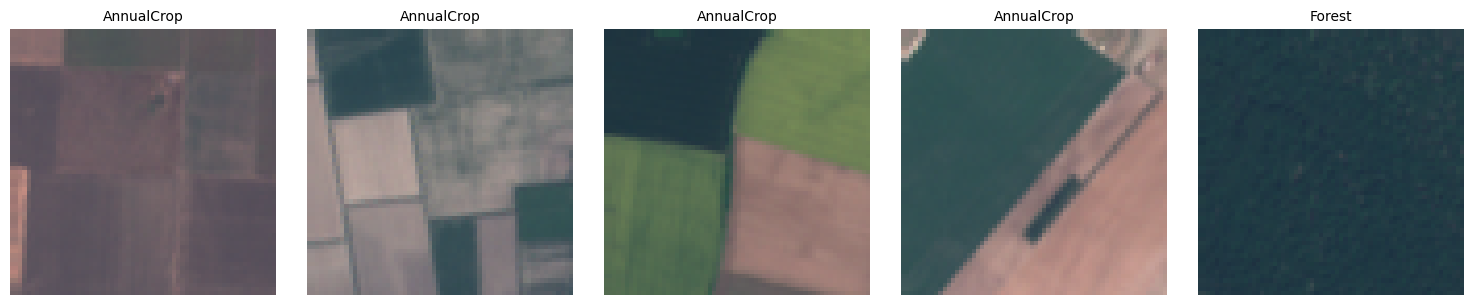

In [ ]:
# Sanity check: LOOK at a few images before trusting any downstream metric. This is the single
# most useful debugging habit in any vision project -- if these don't look like real satellite
# photos, nothing downstream can work, no matter how correct the rest of the code is.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, ax in enumerate(axes):
    img, label = train_ds[i * 500]
    ax.imshow(img)
    ax.set_title(CLASS_NAMES[label], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Load CLIP

We use the standard `openai/clip-vit-base-patch32` checkpoint via Hugging Face `transformers`.
Everything is frozen for now (Phase 1-2); we only add trainable LoRA adapters in Phase 3.

In [ ]:
from transformers import CLIPModel, CLIPProcessor

MODEL_NAME = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(MODEL_NAME).to(device)
clip_processor = CLIPProcessor.from_pretrained(MODEL_NAME)

for p in clip_model.parameters():
    p.requires_grad = False
clip_model.eval()
print("CLIP loaded and frozen.")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP loaded and frozen.


## 3. Phase 1 — Zero-shot baseline

We embed each class with a single hand-written template and classify test images by cosine similarity
between image and text embeddings. This is our floor to beat.

In [ ]:
@torch.no_grad()
def embed_texts(prompts, batch_size=64):
    all_feats = []
    for i in range(0, len(prompts), batch_size):
        batch = prompts[i:i+batch_size]
        inputs = clip_processor(text=batch, return_tensors="pt", padding=True, truncation=True).to(device)
        outputs = clip_model.get_text_features(**inputs)
        # transformers >=5.x: get_text_features returns BaseModelOutputWithPooling,
        # with the projected embedding stored in .pooler_output (not a plain tensor).
        # transformers 4.x returned a plain tensor directly -- this handles both.
        feats = outputs.pooler_output if hasattr(outputs, "pooler_output") else outputs
        feats = F.normalize(feats, dim=-1)
        all_feats.append(feats.cpu())
    return torch.cat(all_feats, dim=0)

@torch.no_grad()
def embed_images(dataset, batch_size=64):
    all_feats, all_labels = [], []
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False,
                         collate_fn=lambda b: (list(zip(*b))[0], list(zip(*b))[1]))
    for imgs, labels in loader:
        inputs = clip_processor(images=list(imgs), return_tensors="pt").to(device)
        outputs = clip_model.get_image_features(**inputs)
        feats = outputs.pooler_output if hasattr(outputs, "pooler_output") else outputs
        feats = F.normalize(feats, dim=-1)
        all_feats.append(feats.cpu())
        all_labels.extend(labels)
    return torch.cat(all_feats, dim=0), torch.tensor(all_labels)

def evaluate(text_feats, image_feats, labels, top_k=1):
    sims = image_feats @ text_feats.T  # N x C
    preds = sims.argmax(dim=1)
    acc = (preds == labels).float().mean().item()
    return acc, preds

In [ ]:
import re

def class_name_to_words(name):
    """Turn a class name like 'HerbaceousVegetation' or 'SeaLake' into properly spaced,
    lowercase words CLIP's text encoder can actually understand ('herbaceous vegetation',
    'sea lake'). A plain .replace('_',' ') does nothing for these run-together names --
    splitting on capital-letter boundaries is what actually fixes it."""
    name = name.replace('_', ' ')
    name = re.sub(r'(?<!^)(?=[A-Z])', ' ', name)
    return name.lower().strip()

simple_prompts = [f"a satellite photo of {class_name_to_words(name)}" for name in CLASS_NAMES]
print(simple_prompts)

text_feats_baseline = embed_texts(simple_prompts)
test_img_feats, test_labels = embed_images(test_ds)

baseline_acc, baseline_preds = evaluate(text_feats_baseline, test_img_feats, test_labels)
print(f"Zero-shot CLIP baseline accuracy: {baseline_acc*100:.2f}%")

torch.save({"image_feats": test_img_feats, "labels": test_labels}, f"{CKPT_DIR}/test_image_feats.pt")

['a satellite photo of annual crop', 'a satellite photo of forest', 'a satellite photo of herbaceous vegetation', 'a satellite photo of highway', 'a satellite photo of industrial', 'a satellite photo of pasture', 'a satellite photo of permanent crop', 'a satellite photo of residential', 'a satellite photo of river', 'a satellite photo of sea lake']
Zero-shot CLIP baseline accuracy: 37.61%


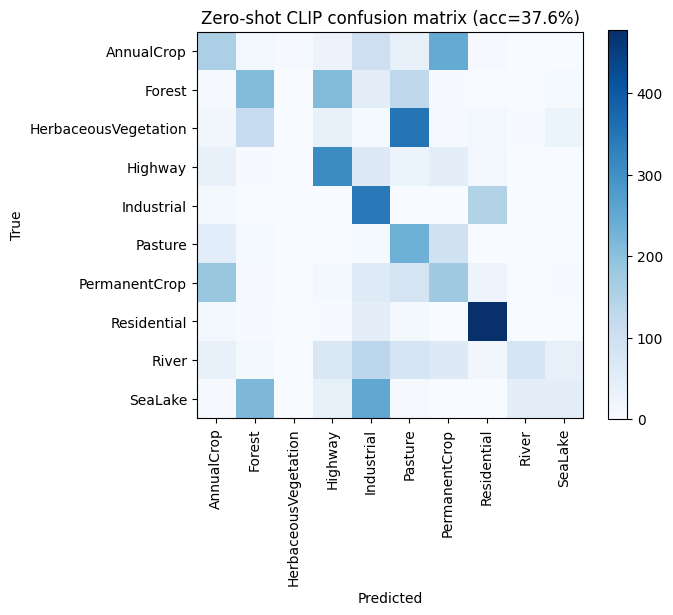

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(test_labels.numpy(), baseline_preds.numpy())
fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASS_NAMES))); ax.set_xticklabels(CLASS_NAMES, rotation=90)
ax.set_yticks(range(len(CLASS_NAMES))); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Zero-shot CLIP confusion matrix (acc={baseline_acc*100:.1f}%)")
plt.colorbar(im)
plt.tight_layout()
plt.savefig(f"{CKPT_DIR}/phase1_confusion_matrix.png", dpi=150)
plt.show()

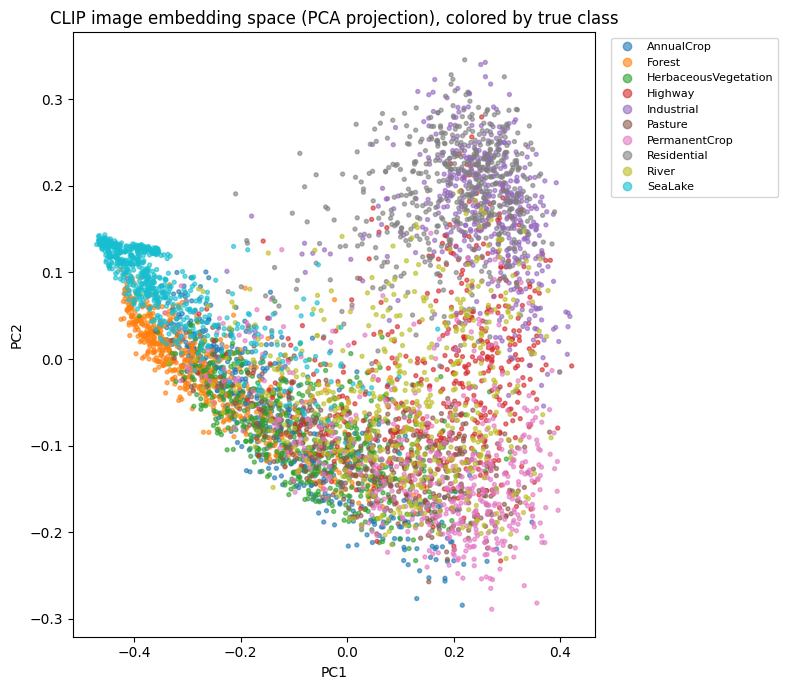

In [ ]:
# Diagnostic: visualize the embedding space itself, not just the final accuracy number.
# This checks whether the vision encoder block is producing genuinely separable representations
# for this domain -- if same-colored points don't cluster at all, no classifier on top (zero-shot
# or LoRA) can be expected to work well, no matter how it's built.
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
img_feats_2d = pca.fit_transform(test_img_feats.numpy())

fig, ax = plt.subplots(figsize=(8, 7))
scatter = ax.scatter(img_feats_2d[:, 0], img_feats_2d[:, 1], c=test_labels.numpy(),
                      cmap="tab10", s=8, alpha=0.6)
handles, _ = scatter.legend_elements(num=len(CLASS_NAMES))
ax.legend(handles, CLASS_NAMES, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.set_title("CLIP image embedding space (PCA projection), colored by true class")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.savefig(f"{CKPT_DIR}/embedding_space_pca.png", dpi=150)
plt.show()

## 4. Phase 2 — LLM-generated descriptive prompts

A single template per class ("a satellite photo of X") is a weak text embedding. We generate several
diverse, visually descriptive sentences per class and average their embeddings, which typically improves
zero-shot accuracy (the same idea as the "Visual Classification via Description from Large Language Models"
line of work — here we test it specifically on remote sensing, which most of that prior work does not cover).

Two options are given below:
- **Option A (default, no setup needed):** a hand-written descriptive prompt bank for the 10 EuroSAT classes.
- **Option B (optional):** generate them live with a small free local LLM (Phi-3-mini, 4-bit quantized) —
  use this if you want the "LLM-generated" part to be literal and reproducible end-to-end.

In [ ]:
# Optional Option B: generate prompts live with a small local LLM instead of the hand-written bank above.
# Skip this cell if you're happy with Option A -- it is NOT required for the rest of the notebook to run.

USE_LOCAL_LLM = True

if USE_LOCAL_LLM:
    import json
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM

    llm_name = "microsoft/Phi-3-mini-4k-instruct"
    llm_tok = AutoTokenizer.from_pretrained(llm_name)
    llm = AutoModelForCausalLM.from_pretrained(
        llm_name,
        torch_dtype=torch.float16,
        device_map="auto"
    )

def generate_descriptions(class_name, n=3):
    clean_name = class_name_to_words(class_name)

    system_prompt = (
        "You are an expert remote sensing and satellite imagery analyst. "
        "Your job is to provide concise, visually distinctive aerial features for visual classification. "
        "Output ONLY short, high-impact visual phrases (5-10 words max per feature). "
        "Do not use full sentences, greetings, or numbering."
    )

    # In-context examples train Phi-3 on the exact format CLIP prefers
    user_prompt = f"""Task: List {n} distinct top-down visual features for satellite classification of the class: '{clean_name}'.

Examples:
Class: Highway
- parallel long asphalt lanes with distinct road markings
- linear continuous infrastructure cutting through vegetation
- sharp geometric ribbons connecting urban regions

Class: Industrial
- large flat-roofed rectangular warehouse buildings
- high-density paved parking lots and shipping docks
- metallic structures and regular grid layout

Class: {clean_name}
-"""

    msgs = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ]

    inputs = llm_tok.apply_chat_template(
        msgs, return_tensors="pt", add_generation_prompt=True, return_dict=True
    ).to(llm.device)

    with torch.no_grad():
        out = llm.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=True,
            temperature=0.25,  # Lower temperature reduces hallucinations
            pad_token_id=llm_tok.eos_token_id,
        )

    prompt_len = inputs["input_ids"].shape[1]
    text = llm_tok.decode(out[0][prompt_len:], skip_special_tokens=True)

    cleaned = []
    for line in text.split("\n"):
        line = line.strip(" -*123456789.").strip()
        if line and len(line.split()) >= 3:
            cleaned.append(line)

    return cleaned[:n]

def build_clip_prompts_for_class(class_name, llm_descriptions):
    clean_name = class_name_to_words(class_name)

    # 1. Domain-specific baseline prompts (Crucial anchor)
    prompts = [
        f"a satellite photo of {clean_name}.",
        f"an aerial top-down view of {clean_name}.",
        f"a sentinel-2 satellite image showing {clean_name}."
    ]

    # 2. Append LLM descriptors wrapped in direct, high-signal templates
    for desc in llm_descriptions:
        if desc:
            prompts.append(f"a satellite photo of {clean_name}, characterized by {desc}.")
            prompts.append(f"a top-down view showing {desc}, a type of {clean_name}.")

    return prompts

if USE_LOCAL_LLM:
    # 1. Generate descriptions
    print("Generating LLM descriptions...")
    LLM_DESCRIPTIVE_PROMPTS = {c: generate_descriptions(c) for c in CLASS_NAMES}

    # 2. Build structured prompt ensembles
    DESCRIPTIVE_PROMPTS = {
        c: build_clip_prompts_for_class(c, LLM_DESCRIPTIVE_PROMPTS[c])
        for c in CLASS_NAMES
    }

    print("\nFormatted Prompt Ensemble:")
    print(json.dumps(DESCRIPTIVE_PROMPTS, indent=2))


config.json:   0%|          | 0.00/967 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.44k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.94M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

Generating LLM descriptions...

Formatted Prompt Ensemble:
{
  "AnnualCrop": [
    "a satellite photo of annual crop.",
    "an aerial top-down view of annual crop.",
    "a sentinel-2 satellite image showing annual crop.",
    "a satellite photo of annual crop, characterized by Uniform green expanses with regular crop rows.",
    "a top-down view showing Uniform green expanses with regular crop rows, a type of annual crop.",
    "a satellite photo of annual crop, characterized by Seasonal color variations in vegetative patterns.",
    "a top-down view showing Seasonal color variations in vegetative patterns, a type of annual crop.",
    "a satellite photo of annual crop, characterized by Regularly spaced, geometric field shapes.",
    "a top-down view showing Regularly spaced, geometric field shapes, a type of annual crop."
  ],
  "Forest": [
    "a satellite photo of forest.",
    "an aerial top-down view of forest.",
    "a sentinel-2 satellite image showing forest.",
    "a satelli

In [ ]:
@torch.no_grad()
def embed_texts_ensemble(prompt_dict, class_order):
    class_feats = []
    for cname in class_order:
        prompts = prompt_dict[cname]
        feats = embed_texts(prompts)          # (k, dim)
        mean_feat = F.normalize(feats.mean(dim=0, keepdim=True), dim=-1)
        class_feats.append(mean_feat)
    return torch.cat(class_feats, dim=0)       # (num_classes, dim)

text_feats_descriptive = embed_texts_ensemble(DESCRIPTIVE_PROMPTS, CLASS_NAMES)
descriptive_acc, descriptive_preds = evaluate(text_feats_descriptive, test_img_feats, test_labels)
print(f"Zero-shot CLIP + descriptive prompt ensemble accuracy: {descriptive_acc*100:.2f}%")
print(f"Improvement over simple-prompt baseline: {(descriptive_acc - baseline_acc)*100:+.2f} points")

Zero-shot CLIP + descriptive prompt ensemble accuracy: 41.54%
Improvement over simple-prompt baseline: +3.93 points


## 5. Phase 3 — Few-shot LoRA adaptation

> Add blockquote



Now we attach trainable LoRA adapters to CLIP's vision encoder attention layers (query/value projections)
and train a small linear classifier head on top, using only **k images per class** (few-shot). Everything
except the LoRA adapters and the linear head stays frozen — this is why it's fast and cheap on a T4.

We repeat for k in {4, 8, 16} to show how accuracy scales with the amount of labeled data — a standard
ablation reviewers expect to see.

In [ ]:
from peft import LoraConfig, get_peft_model

def build_lora_vision_model():
    model = CLIPModel.from_pretrained(MODEL_NAME).to(device)
    for p in model.parameters():
        p.requires_grad = False

    lora_config = LoraConfig(
        r=8,
        lora_alpha=16,
        target_modules=["q_proj", "v_proj"],   # attention projections inside the vision transformer
        lora_dropout=0.05,
        bias="none",
    )
    model.vision_model = get_peft_model(model.vision_model, lora_config)
    return model

class ClipLoraClassifier(nn.Module):
    def __init__(self, clip_lora_model, embed_dim, num_classes):
        super().__init__()
        self.clip = clip_lora_model
        self.head = nn.Linear(embed_dim, num_classes)

    def forward(self, pixel_values):
        vision_out = self.clip.vision_model(pixel_values=pixel_values).pooler_output
        vision_out = self.clip.visual_projection(vision_out)
        vision_out = F.normalize(vision_out, dim=-1)
        return self.head(vision_out)

In [ ]:
def make_k_shot_subset(dataset, k, num_classes, seed=SEED):
    rng = random.Random(seed)
    by_class = {c: [] for c in range(num_classes)}
    for idx in range(len(dataset)):
        _, label = dataset[idx]
        by_class[label].append(idx)
    chosen = []
    for c, idxs in by_class.items():
        rng.shuffle(idxs)
        chosen.extend(idxs[:k])
    return Subset(dataset, chosen)

def collate_fn(batch):
    imgs, labels = zip(*batch)
    pixel_values = clip_processor(images=list(imgs), return_tensors="pt")["pixel_values"]
    return pixel_values, torch.tensor(labels)

In [ ]:
def train_lora_kshot(k, num_epochs=15, lr=1e-3, batch_size=16):
    print(f"\n=== Training LoRA classifier with k={k} shots per class ===")
    train_subset = make_k_shot_subset(train_ds, k, len(CLASS_NAMES))
    loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)

    base = build_lora_vision_model()
    embed_dim = base.config.projection_dim
    model = ClipLoraClassifier(base, embed_dim, len(CLASS_NAMES)).to(device)

    trainable = [p for p in model.parameters() if p.requires_grad]
    n_trainable = sum(p.numel() for p in trainable)
    print(f"Trainable parameters: {n_trainable:,}")

    optimizer = torch.optim.AdamW(trainable, lr=lr)
    model.train()

    for epoch in range(num_epochs):
        total_loss = 0.0
        for pixel_values, labels in loader:
            pixel_values, labels = pixel_values.to(device), labels.to(device)
            logits = model(pixel_values)
            loss = F.cross_entropy(logits, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"  epoch {epoch+1}/{num_epochs}  loss={total_loss/len(loader):.4f}")

    ckpt_path = f"{CKPT_DIR}/lora_k{k}.pt"
    torch.save(model.state_dict(), ckpt_path)
    print(f"Saved checkpoint: {ckpt_path}")
    return model

In [ ]:
@torch.no_grad()
def evaluate_lora_model(model, dataset, batch_size=64):
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
    correct, total = 0, 0
    for pixel_values, labels in loader:
        pixel_values, labels = pixel_values.to(device), labels.to(device)
        logits = model(pixel_values)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return correct / total

In [ ]:
lora_results = {}
for k in [4, 8, 16]:
    model_k = train_lora_kshot(k)
    acc_k = evaluate_lora_model(model_k, test_ds)
    lora_results[k] = acc_k
    print(f"k={k}: test accuracy = {acc_k*100:.2f}%")
    del model_k
    torch.cuda.empty_cache()

print("\nLoRA few-shot results:", lora_results)


=== Training LoRA classifier with k=4 shots per class ===


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Trainable parameters: 300,042
  epoch 1/15  loss=2.3091
  epoch 5/15  loss=2.1369
  epoch 10/15  loss=1.8444
  epoch 15/15  loss=1.5879
Saved checkpoint: /content/drive/MyDrive/cv_project_checkpoints/lora_k4.pt
k=4: test accuracy = 77.04%

=== Training LoRA classifier with k=8 shots per class ===


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Trainable parameters: 300,042
  epoch 1/15  loss=2.3034
  epoch 5/15  loss=2.0029
  epoch 10/15  loss=1.5817
  epoch 15/15  loss=1.2128
Saved checkpoint: /content/drive/MyDrive/cv_project_checkpoints/lora_k8.pt
k=8: test accuracy = 88.63%

=== Training LoRA classifier with k=16 shots per class ===


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Trainable parameters: 300,042
  epoch 1/15  loss=2.2754
  epoch 5/15  loss=1.6790
  epoch 10/15  loss=1.0093
  epoch 15/15  loss=0.5709
Saved checkpoint: /content/drive/MyDrive/cv_project_checkpoints/lora_k16.pt
k=16: test accuracy = 91.19%

LoRA few-shot results: {4: 0.7703703703703704, 8: 0.8862962962962962, 16: 0.9118518518518518}


## 6. Phase 4 — Cross-domain generalization test

This is the part that turns the project from "I fine-tuned CLIP" into a real research contribution:
does the model you just adapted on EuroSAT still work on a *different* remote-sensing dataset, with
different sensors/resolution, without any retraining?

We use **RESISC45** (NWPU-RESISC45), a 45-class scene classification dataset, and evaluate only on the
subset of classes that semantically overlap with EuroSAT (forest, river, highway/freeway, residential,
industrial-type classes). This tests true out-of-distribution generalization rather than just re-testing
on more of the same data.

**Note on downloading RESISC45:** unlike EuroSAT, RESISC45 is not always available for fully automatic
download (licensing). Try the Hugging Face Hub first (search "resisc45" on huggingface.co/datasets — the
exact dataset repo id can change, so check what's currently available); if that fails, torchgeo's
`RESISC45` class documents the manual-download steps.

In [ ]:
# Try loading a RESISC45 mirror from the Hugging Face Hub. If the dataset id below no longer exists,
# search https://huggingface.co/datasets?search=resisc45 for a current mirror and swap the id in.
from datasets import load_dataset

RESISC_HF_ID = "timm/resisc45"  # check huggingface.co/datasets for the current best mirror if this fails

try:
    resisc = load_dataset(RESISC_HF_ID, split="train")
    print(resisc)
except Exception as e:
    print("Could not auto-load RESISC45 from the Hub. See the markdown note above for manual steps.")
    print("Error:", e)
    resisc = None

README.md:   0%|          | 0.00/3.11k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  255MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.1MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/18900 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/6300 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6300 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'label', 'image_id'],
    num_rows: 18900
})


In [ ]:
# Map overlapping RESISC45 classes onto their EuroSAT equivalents. Adjust this dict to match whatever
# label names your chosen RESISC45 source actually uses (print resisc.features to check).
RESISC_TO_EUROSAT = {
    "forest": "Forest",
    "river": "River",
    "freeway": "Highway",
    "industrial_area": "Industrial",
    "dense_residential": "Residential",
}

if resisc is not None:
    label_names = resisc.features["label"].names
    print("RESISC45 label names sample:", label_names[:10], "...")

    overlap_indices = {name: label_names.index(name) for name in RESISC_TO_EUROSAT if name in label_names}
    print("Usable overlapping classes:", overlap_indices)

RESISC45 label names sample: ['airplane', 'airport', 'baseball_diamond', 'basketball_court', 'beach', 'bridge', 'chaparral', 'church', 'circular_farmland', 'cloud'] ...
Usable overlapping classes: {'forest': 13, 'river': 32, 'freeway': 14, 'industrial_area': 18, 'dense_residential': 11}


In [ ]:
@torch.no_grad()
def evaluate_cross_domain(model, hf_dataset, overlap_indices, resisc_to_eurosat, class_names, max_per_class=100):
    model.eval()
    eurosat_idx_of = {name: i for i, name in enumerate(class_names)}

    imgs, labels = [], []
    counts = {k: 0 for k in overlap_indices}
    for ex in hf_dataset:
        lbl = ex["label"]
        for resisc_name, resisc_lbl in overlap_indices.items():
            if lbl == resisc_lbl and counts[resisc_name] < max_per_class:
                imgs.append(ex["image"].convert("RGB"))
                labels.append(eurosat_idx_of[resisc_to_eurosat[resisc_name]])
                counts[resisc_name] += 1
        if all(c >= max_per_class for c in counts.values()):
            break

    print("Collected per-class counts:", counts)
    if not imgs:
        print("No matching samples found -- check RESISC_TO_EUROSAT names against label_names above.")
        return None

    pixel_values = clip_processor(images=imgs, return_tensors="pt")["pixel_values"].to(device)
    labels_t = torch.tensor(labels).to(device)

    logits = model(pixel_values)
    preds = logits.argmax(dim=1)
    acc = (preds == labels_t).float().mean().item()
    print(f"Cross-domain (RESISC45 -> EuroSAT-trained model) accuracy on overlapping classes: {acc*100:.2f}%")
    return acc

if resisc is not None and overlap_indices:
    best_k = max(lora_results, key=lora_results.get)
    best_model = build_lora_vision_model()
    embed_dim = best_model.config.projection_dim
    classifier = ClipLoraClassifier(best_model, embed_dim, len(CLASS_NAMES)).to(device)
    classifier.load_state_dict(torch.load(f"{CKPT_DIR}/lora_k{best_k}.pt"))

    cross_domain_acc = evaluate_cross_domain(classifier, resisc, overlap_indices, RESISC_TO_EUROSAT, CLASS_NAMES)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Collected per-class counts: {'forest': 100, 'river': 100, 'freeway': 100, 'industrial_area': 100, 'dense_residential': 100}
Cross-domain (RESISC45 -> EuroSAT-trained model) accuracy on overlapping classes: 64.60%


## 7. Results summary

In [ ]:
import pandas as pd

rows = [
    {"Method": "Zero-shot CLIP (simple prompt)", "Accuracy": baseline_acc},
    {"Method": "Zero-shot CLIP (LLM/descriptive prompt ensemble)", "Accuracy": descriptive_acc},
]
for k, acc in lora_results.items():
    rows.append({"Method": f"LoRA few-shot (k={k})", "Accuracy": acc})

results_df = pd.DataFrame(rows)
results_df["Accuracy (%)"] = (results_df["Accuracy"] * 100).round(2)
print(results_df[["Method", "Accuracy (%)"]].to_string(index=False))

results_df.to_csv(f"{CKPT_DIR}/final_results.csv", index=False)

                                          Method  Accuracy (%)
                  Zero-shot CLIP (simple prompt)         37.61
Zero-shot CLIP (LLM/descriptive prompt ensemble)         41.54
                             LoRA few-shot (k=4)         77.04
                             LoRA few-shot (k=8)         88.63
                            LoRA few-shot (k=16)         91.19


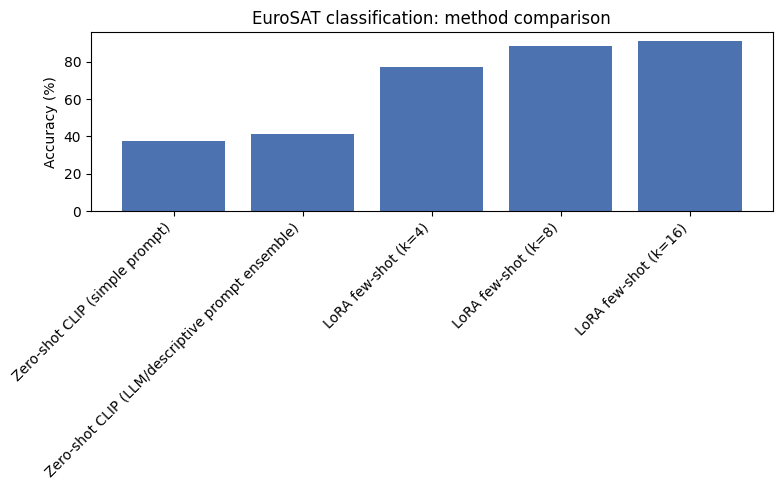

In [ ]:
fig, ax = plt.subplots(figsize=(8,5))
ax.bar(results_df["Method"], results_df["Accuracy (%)"], color="#4C72B0")
ax.set_ylabel("Accuracy (%)")
ax.set_title("EuroSAT classification: method comparison")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{CKPT_DIR}/final_results_chart.png", dpi=150)
plt.show()

## 8. Next steps: turning this into a write-up

1. **Related work**: cite the CLIP paper, a LoRA paper, and the "classification via LLM-generated
   descriptions" line of work you're extending into remote sensing.
2. **Ablations to include**: prompt ensemble size (1 vs 3 vs 5 descriptions/class), LoRA rank (r=4/8/16),
   and the k-shot curve you already produced above.
3. **Failure analysis**: look at the confusion matrix from Phase 1 and the cross-domain results from
   Phase 4 — which classes fail, and why? (e.g. visually similar crop types, sensor/resolution mismatch
   between EuroSAT and RESISC45). This discussion is often what reviewers value most.
4. **Write-up structure**: Abstract, Introduction, Related Work, Method, Experiments, Results, Discussion
   & Limitations, Conclusion — see the companion `PROJECT_GUIDE.md` file for a fillable template.
5. Push the cleaned-up code + this notebook + README to a public GitHub repo, then consider an arXiv
   submission (you'll need an endorsement for a first cs.CV submission — ask your thesis supervisor) or a
   relevant workshop with open submissions (e.g. an earth-observation or efficient-ML workshop at a major
   CV conference).